<div style="background:#152238;color:white;border-radius:14px;padding:28px 32px;">
 <div style="color:#9de2dc;letter-spacing:2px;font-size:12px;font-weight:bold;">AI ALGORITHMS · LOCAL SEARCH LAB</div>

 <h1 align="center"><b>Lab session 3:</b> Local Search & Genetic Algorithm<br><div style="color:#eebe5c;letter-spacing:2px;font-size:14px;font-weight:bold;">Hill Climbing · Simulated Annealing · Genetic Algorithm</div></h1>
 </div>

## Start with the map

A delivery vehicle must serve all **24 locations** below. The thin grey lines show the **276 possible connections**: from any city, a direct trip to any other city is allowed. The gold marker is the depot, city 0.

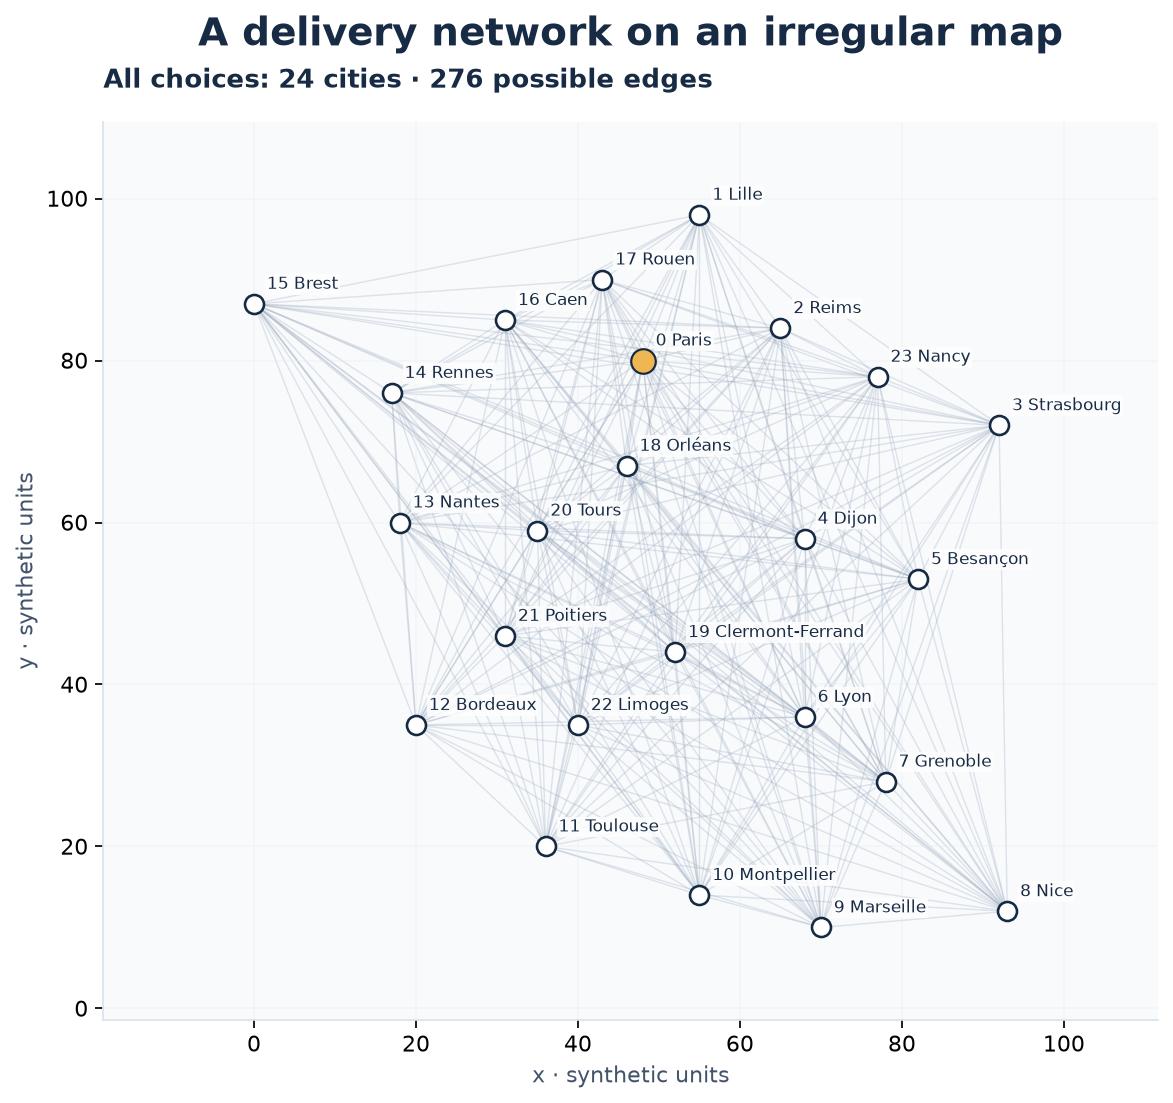

The names are French cities on **synthetic coordinates**: distances are illustrative units, not kilometres or road distances. The positions stay fixed throughout the lab.

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q0 · Read the network before searching</strong><br>Without coding: (1) Are the grey lines already a delivery route? (2) Sketch a route that visits each city once and returns to the depot. (3) Which detour would you try to shorten first? Is your route the best possible, and how would you know?
</div>

**Your answer:** …

## Your route through the lab

You will **model** a tour, **implement** three local-search mechanisms on the same problem, **explain** one decision in each trace, **defend** an experimental comparison, and finally **transfer** two of the methods to a Sudoku.

| Step | Question | Evidence to produce |
|:---|:---|:---|
| 1. Model | What is a valid solution and its cost? | A checked tour, Q1 |
| 2. Moves | How does one tour become a neighbour? | Two neighbourhoods, a before/after figure, Q3 |
| 3. Hill Climbing | What does greedy improvement achieve? | Implementation, trace, Q4 |
| 4. Simulated Annealing | When can a worse move help? | Acceptance rule, two schedules, trace, Q5–Q6 |
| 5. Genetic Algorithm | How can several tours evolve together? | Operators, population loop, Q7–Q8 |
| 6. Compare | What does the evidence support? | Repeated runs, a qualified recommendation |
| 7. Your turn | Do the methods and their settings transfer to a Sudoku? | Your own model, HC + GA or SA + GA, a tuned and frozen comparison, a justified discussion |

One three-hour session covers one working configuration of each method. The controlled studies E1–E3 with 20 seeds, the frozen final test and the synthesis (Q9–Q12) are personal work to finish before the first oral assessment lab (before lab 4 session), as is the Sudoku exercise of Section 7, a free implementation from a statement.

Labels: **OBSERVE** (teal) read a figure or a trace · **IMPLEMENT** (orange) write the requested code · **EXPLAIN** (purple) answer with evidence. Q are written questions, I implementations, E controlled studies. Keep each answer next to the cell that produced its evidence.

<div style="border-left:5px solid #245b96;background:#eff5fc;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#245b96;">SETUP · Environment</strong><br>Open this notebook next to <code>search_lab/</code> with Python 3.10+ and JupyterLab or Notebook. If a package is missing, run <code>%pip install -r requirements.txt</code> and restart the kernel. The helpers contain the data, the checks, the run recorder, the figures and the benchmark plumbing; they contain no search algorithm. Cells that call a function you have not written yet raise <code>NotImplementedError</code> until you complete it. After updating the lab files, rerun the imports cell: it reloads the helpers.
</div>

In [ ]:
%matplotlib inline
import math
import json
import importlib
import sys
from functools import partial
import numpy as np
import pandas as pd
from IPython.display import display

# Refresh the helpers after a file update in a running kernel (dependency order).
importlib.invalidate_caches()
for _module_name in ("search_lab.data", "search_lab.checks", "search_lab.recording",
                     "search_lab.experiments", "search_lab.visuals", "search_lab.sudoku", "search_lab"):
    if _module_name in sys.modules:
        importlib.reload(sys.modules[_module_name])

from search_lab import (
    FRENCH_CITIES, run_search, as_method, animation_demo,
    check_neighbor, check_neighborhood, check_crossover, tour_report, cycle_diversity,
    show_network, show_tour, show_move, plot_trace, animate_run, save_player,
    plot_schedules, benchmark, summarize, paired_effect, plot_results,
    export_results, environment,
)

SEED = 7
# Maximum number of steps of each method: every run, cooling schedule, study and the final test use them.
# One step evaluates 252 tours in hill climbing (one full 2-opt scan), 1 tour in simulated annealing (one proposal)
# and 39 tours in the genetic algorithm (one generation, P = 40 with one elite): about 5,000 tours per run for each.
HC_STEPS = 20
SA_STEPS = 5000
GA_STEPS = 125
DEBUG_SEEDS = list(range(5))
TUNING_SEEDS = list(range(20))
TEST_SEEDS = list(range(100, 120))  # Reserved for the final comparison.
display(environment())

## 1 · The problem: a closed tour

Choose a **minimum-cost closed tour**: leave the depot, visit every other city exactly once, return to the depot. Distances are Euclidean, the graph is complete and symmetric.

A solution is a permutation $\pi$ of the IDs $0,\ldots,n-1$ with city 0 kept first (this removes equivalent rotations). The return to 0 is **implicit**: do not append 0 to the array.

$$C(\pi)=\sum_{k=0}^{n-1} d\bigl(\pi_k,\pi_{(k+1)\bmod n}\bigr), \qquad \min_\pi C(\pi).$$

`[0, 2, 1, 3]` means $0\to2\to1\to3\to0$: $n$ stored IDs, $n$ edges. A valid tour is one cycle with degree 2 at every city; a crossing of drawn lines is neither a city nor a connection. After fixing the depot and identifying a tour with its reverse, $(n-1)!/2$ distinct tours remain, about $1.3\cdot10^{22}$ for 24 cities. We will look for good tours under a limited number of cost evaluations; none of the methods below certifies a global optimum.

The class below is the whole model: the cities and their distances, a random tour, the cost of a tour and its edges. `move_pairs` lists the position pairs (i, j) that define one move in Section 2; the pair that only reads the same cycle backwards is excluded. You will add the moves (Section 2) and the search algorithms (Sections 3–5) on top of it.

In [ ]:
class TSP:
    """A delivery tour: visit every city once and come back to the depot.
    A tour is a NumPy array of city IDs with city 0 (the depot) in the first position."""

    def __init__(self, cities):
        self.names = tuple(cities)                                  # city ID -> name
        self.xy = np.array(list(cities.values()), dtype=float)      # city ID -> (x, y)
        self.n = len(self.names)
        self.distances = np.linalg.norm(self.xy[:, None] - self.xy[None, :], axis=2)   # n x n Euclidean distances

    def random_tour(self, rng):
        """A random tour: city 0, then the other cities in random order."""
        return np.r_[0, rng.permutation(np.arange(1, self.n))]

    def is_valid(self, tour):
        """True when the tour contains every city ID exactly once."""
        tour = np.asarray(tour)
        return (
            tour.ndim == 1  # Check that tour is a 1D array
            and np.issubdtype(tour.dtype, np.integer)  # Check that elements are integers
            and np.array_equal(np.sort(tour), np.arange(self.n))  # Check that tour is a valid permutation of 0 to n-1
            )

    def cost(self, tour):
        """Length of the closed tour: n edges, the last one from the last city back to city 0."""
        if not self.is_valid(tour):
            # Raise an error if the tour is invalid
            raise ValueError("A tour must contain every city ID exactly once.")
        tour = np.asarray(tour) # Convert the tour to a NumPy array

        return float(self.distances[tour, np.roll(tour, -1)].sum())

    def edges(self, tour):
        """The n edges (a, b) of the tour, the last one back to city 0."""
        tour = np.asarray(tour) # Convert the tour to a NumPy array
        # Pair each city with the next one to create the edges
        return [(int(a), int(b)) for a, b in zip(tour, np.roll(tour, -1))]

    def move_pairs(self, move="two_opt"):
        """All position pairs (i, j) with 1 <= i < j < n that define one move; position 0 (the depot) never moves.
        Reversing the whole tail 1..n-1 only reads the same cycle backwards, so 2-opt excludes that pair
        (on four cities, so does swap)."""
        pairs = [(i, j) for i in range(1, self.n) for j in range(i + 1, self.n)]
        if move == "two_opt" or self.n == 4:
            pairs.remove((1, self.n - 1))
        return pairs

In [ ]:
# Create the TSP problem
problem = TSP(FRENCH_CITIES)

# Generate a reproducible random tour
initial = problem.random_tour(np.random.default_rng(SEED))

display(show_network(FRENCH_CITIES, initial)) # Display the tour on the city network

print("Stored permutation:", initial) # Print the city visit order
print("Closed-tour cost:", round(problem.cost(initial), 2)) # Print the total tour distance

print("Possible undirected edges:", problem.n * (problem.n - 1) // 2) # Count all possible undirected edges
print("Distinct tours:", math.factorial(problem.n - 1) // 2) # Count distinct tours
display(tour_report(problem, initial).head(6)) # Display the first six rows of the tour report

assert (tour_report(problem, initial).degree == 2).all() # Verify that every city has exactly two connections

<div style="border-left:5px solid #087f8c;background:#eef9f8;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#087f8c;">OBSERVE · Available graph versus chosen tour</strong><br>The left panel shows the input graph, the right panel one chosen tour on the same coordinates. Its crossings and long jumps are a starting point for improvement; they do not make the permutation invalid.
</div>

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q1 · Representation and feasibility</strong><br>(a) Why does the array hold n IDs but the tour n edges? (b) Why does "degree 2 everywhere" alone not prove a single tour? (c) Why does fixing the first city lose no tour?
</div>

**Your answer:** …

## 2 · Moves and neighbourhoods

A city's neighbours are its predecessor and successor **inside one tour**. A neighbouring **solution** is a different complete tour obtained by one move. The set of all tours reachable by one move is the **neighbourhood** of the current tour; hill climbing scans it entirely, simulated annealing samples one element of it.

| Move | Action on positions $1\ldots n-1$ (the depot stays at 0) | Example |
|:---|:---|:---|
| Swap | Exchange the cities at positions i and j | `[0,1,2,3,4,5,6] → [0,1,4,3,2,5,6]` (positions 2 and 4) |
| 2-opt | Reverse the segment from i to j included | `[0,1,2,3,4,5,6] → [0,1,5,4,3,2,6]` (positions 2…5) |
| ... | Other neighbourhood moves (e.g., 3-opt, Or-opt) |  |

The two examples coincide on a three-city segment; on a longer segment swap exchanges only the endpoints while 2-opt reverses the interior order too. In a symmetric TSP a 2-opt move replaces exactly two edges of the tour, a swap up to four.

In [ ]:
# Demonstrate a single 2-opt move by reversing part of the route.
# This move is chosen manually for illustration; no optimization solver is used.

move_before = initial.copy()
move_after = move_before.copy()

# Reverse positions 2 through 7 (the end index 8 is excluded).
move_after[2:8] = move_after[2:8][::-1]

# Visualize the move and print the routes before and after the reversal.
display(show_move(problem, move_before, move_after, title="Reverse positions 2…7 (Python slice 2:8)"))
print("Before:", move_before)
print("After: ", move_after)

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I1 · Two neighbourhoods</strong><br>Complete <code>MyTSP</code>: <code>apply_move(tour, i, j, move)</code> returns a <b>new</b> array with positions i and j exchanged (<code>"swap"</code>) or the segment i…j reversed, both ends included (<code>"two_opt"</code>); <code>neighbors(tour, move)</code> returns the list of all neighbours, one per pair of <code>self.move_pairs(move)</code>; <code>random_neighbor(tour, rng, move)</code> returns one neighbour for a pair drawn uniformly with <code>rng</code>. Never modify the input tour.
</div>

In [ ]:
class MyTSP(TSP):
    """The two neighbourhoods used by every algorithm of this lab."""

    def apply_move(self, tour, i, j, move="two_opt"):
        """A NEW tour: positions i and j exchanged (swap) or the segment i..j reversed (2-opt)."""
        raise NotImplementedError("I1: implement apply_move")

    def neighbors(self, tour, move="two_opt"):
        """Every tour reachable by one move: the complete neighbourhood."""
        raise NotImplementedError("I1: implement neighbors")

    def random_neighbor(self, tour, rng, move="two_opt"):
        """One neighbour, uniformly chosen in the complete neighbourhood."""
        raise NotImplementedError("I1: implement random_neighbor")


problem = MyTSP(FRENCH_CITIES)

In [ ]:
for move in ("swap", "two_opt"):
    print(f"{move}: {check_neighborhood(problem, problem.neighbors, expected_size=len(problem.move_pairs(move)), move=move)}")
    print(f"{move}: {check_neighbor(problem, partial(problem.random_neighbor, move=move))}")
rng = np.random.default_rng(SEED)
display(show_move(problem, initial, problem.random_neighbor(initial, rng, "swap"), title="One swap"))
display(show_move(problem, initial, problem.random_neighbor(initial, rng, "two_opt"), title="One 2-opt reversal"))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q3 · What changed?</strong><br>On your two figures, identify the changed positions and the changed edges.
</div>

**Your answer:** …

### 2.2 Run a search and watch it

Every algorithm of this lab is a plain function: it works on `problem`, keeps its own current tour, and performs at most `max_steps` steps. It may stop earlier when its own rule says so; it returns nothing.

```python
def my_search(problem, rng, initial, max_steps, ...):   # rng: a NumPy random generator; initial: the starting tour
    current, current_cost = initial, problem.cost(initial)
    for step in range(max_steps):
        ...                                              # one step of the algorithm, written like its pseudo-code
```

`run_search(my_search, problem, SEED, initial, max_steps=..., ...)` runs it and returns a **run**: `run.best_tour`, `run.best_cost`, `run.steps` (the steps performed), `run.evaluations` (the tours evaluated), and the trace that `plot_trace(run)` and `animate_run(problem, run)` display (`run.events` holds one dictionary per decision). Inside your function, `problem` is the same object as outside, with a counter attached:

| Inside your function | What it does |
|:---|:---|
| `problem.cost(tour)` | The cost of a tour; **counts one evaluation** and archives the best tour seen so far |
| `problem.neighbors(tour, move)` · `problem.random_neighbor(tour, rng, move)` | Your I1 methods; they also count one step and tell the recorder that `tour` is the **current** tour, so the trace can show the current tour, the candidate, Δ and the decision |
| `problem.random_tour(rng)` | A random tour (after the start: a random restart) |
| `problem.snapshot(population)` | Genetic algorithm only: record the population after initialisation and after each generation (one step) |

Every evaluated tour counts in `run.evaluations`: the initial tour, every scanned neighbour, every rejected proposal, every child. Keep the cost of a tour you have already evaluated instead of calling `problem.cost` on it again. The player below replays a **guided example**: the starting tour of Section 1, then eleven hand-authored 2-opt proposals accepted or rejected by hand, twelve frames in all. Your runs will produce their own trace with the same controls.

In [ ]:
demo = animation_demo(problem)
display(animate_run(problem, demo, layout="geometry"))

<div style="border-left:5px solid #087f8c;background:#eef9f8;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#087f8c;">OBSERVE · Read one animation frame</strong><br>Step through the twelve frames with the arrows (Play/Pause, timeline and speed control also work) and read the decision box at each frame: the proposal, Δ, accepted or rejected, and a note saying what to look at. Select Current, Best archived or Candidate to see one tour at a time: from frame 7 the best archived tour differs from the current one. Inspect highlights a city's two actual edges; the circular view is only a topology aid. The moves and decisions of this example are hand-authored, not algorithm results; your runs will produce their own. If scripts are blocked, rerun the notebook or open <code>Animation_Demo.html</code>.
</div>

## 3 · Hill Climbing: move to the best neighbour

Hill climbing keeps one current tour and moves to its **best neighbour** as long as that neighbour is strictly better. When no neighbour improves the current tour, the search stops: the tour is a **local optimum** for this neighbourhood.

```text
current ← initial tour (evaluated)
repeat at most max_steps times:
    neighbour ← the lowest-cost tour of neighbors(current)      # one full scan = one step
    if cost(neighbour) ≥ cost(current): stop                    # no neighbour improves the tour
    current ← neighbour
```

Each step evaluates the whole neighbourhood (252 tours for 2-opt on 24 cities). A tour that no neighbour improves is a local optimum for the chosen neighbourhood only. A **random restart** (a new random tour, keeping the best tour seen) is the simplest way to leave it.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I2 · Hill Climbing</strong><br>Implement the pseudo-code. Evaluate the starting tour, then repeat at most <code>max_steps</code> times: scan the whole neighbourhood, <code>problem.neighbors(current, move)</code>, evaluating every neighbour with <code>problem.cost</code>, and move to the best neighbour only when Δ &lt; 0. When no neighbour improves the current tour, stop (<code>break</code>), unless <code>restarts=True</code>: then continue from a new <code>problem.random_tour(rng)</code> (evaluate it first). The function returns nothing: the recorder archives the best tour and draws the trace by itself.
</div>

In [ ]:
def hill_climbing(problem, rng, initial, max_steps, move="two_opt", restarts=False):
    """I2: move to the best neighbour while it improves, for at most max_steps steps (or restart)."""
    raise NotImplementedError("I2: implement hill_climbing")

In [ ]:
hc_run = run_search(hill_climbing, problem, SEED, initial, max_steps=HC_STEPS, move="two_opt")
accepted_moves = [e for e in hc_run.events if e["accepted"]]
assert np.all(np.diff([e["cost"] for e in hc_run.events]) <= 1e-9)
display(animate_run(problem, hc_run))
display(show_tour(problem, hc_run.best_tour, title="HC best found"))
print(f"{hc_run.steps} of {HC_STEPS} steps · {hc_run.evaluations} evaluations · {len(accepted_moves)} accepted moves "
      f"· cost {hc_run.best_cost:.2f} (initial {hc_run.events[0]['cost']:.2f})")

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q4 · Read a greedy trace</strong><br>How many steps were accepted, how many evaluations did each step cost, and why did the run stop before <code>max_steps</code>? Explain the shape of the Δ plot. What does the stop prove, and what does it not prove? Check with <code>problem.neighbors(hc_run.best_tour, "swap")</code> whether the returned tour is also a local optimum for the swap neighbourhood.
</div>

**Your answer:** …

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · E1 · Hill Climbing studies</strong><br> (a) compare swap and 2-opt with the same seeds and <code>HC_STEPS</code>; (b) with the 2-opt neighbourhood, compare a single climb with random restarts, both with <code>max_steps = 3 × HC_STEPS</code>.
</div>

## 4 · Simulated Annealing: accept some worse moves

Simulated annealing draws **one random neighbour** per step and may accept it even when it is worse. With $\Delta = C(\text{candidate}) - C(\text{current})$ and a temperature $T$:

$$p(\text{accept})=\begin{cases}1 & \Delta\le 0\\ e^{-\Delta/T} & \Delta>0,\ T>0\\ 0 & \Delta>0,\ T=0.\end{cases}$$

Draw $u\sim U[0,1)$ and accept when $u<p$. The temperature follows a **schedule**: high at first (many worse moves accepted), low at the end (almost none); at $T=0$ only improvements and ties are accepted. Over the $H=\text{max\_steps}$ proposals, $t=0,\ldots,H-1$:

- **geometric:** $T(t)=T_0\,\alpha^{t}$ with $\alpha=(T_f/T_0)^{1/(H-1)}$, so that $T(H-1)=T_f$;
- **linear:** $T(t)=T_0-(T_0-T_f)\,t/(H-1)$.

Both start at $T_0$ and end at $T_f$; they differ in between. Temperature has the units of a cost difference. The current tour may get worse; the **best evaluated tour** never does. The recorder archives it: the answer of a run is `run.best_tour`, not the last current tour.

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q5 · Predict an acceptance decision</strong><br>For Δ = +10, compute p at T = 20 and at T = 1. With u = 0.4, which move is accepted? What happens for Δ = −10, Δ = 0 and T = 0? If all distances were multiplied by 100, how would you keep the same acceptance behaviour?
</div>

**Your answer:** …

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I3 · Acceptance and two cooling schedules</strong><br>Implement the three pure functions below. Reject negative or non-finite temperatures and invalid schedule parameters (T0 &gt; 0, 0 ≤ Tf ≤ T0; geometric cooling needs Tf &gt; 0). The <code>horizon</code> argument is the number of proposals, so that the last temperature equals Tf. Check the start and end values before running SA.
</div>

In [ ]:
def acceptance_probability(delta, temperature):
    """1 for an improvement or a tie, exp(-delta / T) for a worse move, 0 when T = 0."""
    raise NotImplementedError("I3: implement acceptance_probability")


def cooling_geometric(t, *, horizon, T0=30.0, Tf=0.1):
    """T(t) = T0 * alpha ** t, with alpha chosen so that T(horizon - 1) = Tf."""
    raise NotImplementedError("I3: implement cooling_geometric")


def cooling_linear(t, *, horizon, T0=30.0, Tf=0.1):
    """T(t) decreases by the same amount at each proposal, from T0 down to Tf."""
    raise NotImplementedError("I3: implement cooling_linear")

In [ ]:
assert np.isclose(acceptance_probability(10, 20), np.exp(-0.5))
assert acceptance_probability(10, 0) == 0
assert acceptance_probability(-10, 0) == 1
assert acceptance_probability(0, 0) == 1
H = SA_STEPS                                  # one proposal per step
schedules = {
    "Geometric": partial(cooling_geometric, horizon=H, T0=30, Tf=0.1),
    "Linear": partial(cooling_linear, horizon=H, T0=30, Tf=0.1),
}
for schedule in schedules.values():
    assert np.isclose(schedule(0), 30) and np.isclose(schedule(H - 1), 0.1)
    assert np.all(np.diff([schedule(t) for t in range(0, H, 50)]) <= 0)
print("Acceptance and schedule checks passed. alpha =", round((0.1 / 30) ** (1 / (H - 1)), 6))
display(plot_schedules(schedules, steps=H))

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I4 · Simulated Annealing</strong><br>One evaluation for the initial tour, one per proposal. Perform <code>max_steps</code> steps and build the chosen schedule with <code>horizon = max_steps</code>; at each step t read T, draw one neighbour with <code>problem.random_neighbor(current, rng, move)</code>, evaluate it, compute Δ and p, draw u with <code>rng.random()</code> and update the current tour if accepted. The recorder keeps the best tour; your function only moves the current one and returns nothing.
</div>

In [ ]:
def simulated_annealing(problem, rng, initial, max_steps, move="two_opt", cooling="geometric", T0=30.0, Tf=0.1):
    """I4: one random neighbour per step; a worse move is accepted with probability exp(-delta / T)."""
    raise NotImplementedError("I4: implement simulated_annealing")

In [ ]:
sa_run = run_search(simulated_annealing, problem, SEED, initial, max_steps=SA_STEPS, move="two_opt",
                    cooling="geometric", T0=30, Tf=0.1)
assert np.all(np.diff(sa_run.history) <= 1e-9)
display(plot_trace(sa_run))
display(animate_run(problem, sa_run))
display(show_tour(problem, sa_run.best_tour, title="SA best found"))
# One row per proposal (row 0 of the events is the initial tour). T and p are read from your schedule and
# your acceptance rule at each proposal: the recorder itself only sees the tours, their costs and the decisions.
sa_decisions = pd.DataFrame(sa_run.events)
proposals = sa_decisions.iloc[1:].copy()
proposals["temperature"] = [cooling_geometric(t, horizon=SA_STEPS, T0=30, Tf=0.1) for t in range(len(proposals))]
proposals["probability"] = [acceptance_probability(d, T) for d, T in zip(proposals.delta, proposals.temperature)]
worse_accepted = proposals[(proposals.delta > 0) & (proposals.accepted == True)]
print(f"{len(worse_accepted)} worse moves accepted out of {int((proposals.delta > 0).sum())} worse proposals; "
      f"final current {sa_decisions.cost.iloc[-1]:.2f}, best {sa_run.best_cost:.2f}")
display(worse_accepted[["evaluations", "delta", "temperature", "probability", "cost", "best"]].head())

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q6 · Exploration and cooling</strong><br>Take one accepted worse move from the table and verify exp(−Δ/T). Why do the current and best curves separate? What are the risks of cooling too fast and of staying hot too long? If no worse move had been accepted, what would you inspect first?
</div>

**Your answer:** …

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · E2 · Simulated Annealing studies</strong><br>Compare, one factor at a time with the 2-opt neighbourhood, the same 20 seeds and <code>SA_STEPS</code>: (a) geometric versus linear cooling with the same endpoints; (b) T0 = 5, 30, 100 at Tf = 0.1; (c) Tf = 0.01, 0.1, 5 at T0 = 30 (a higher Tf cools more slowly). Plot the schedules and discuss cost, variability, convergence and time.
</div>

## 5 · Genetic Algorithm: evolve a population of tours

A genetic algorithm keeps a **population** of tours (permutation encoding, city 0 fixed) and evaluates each one; the cost is the fitness to minimise. One generation: **select** parents, **cross** them over, **mutate** the child, **evaluate** it, **replace** the population while keeping the best individuals.

| Step | Reference choice |
|:---|:---|
| Initialisation | P tours: the shared initial tour plus P−1 random tours, all evaluated |
| Selection | tournament (best of k random individuals), roulette wheel (probability ∝ fitness, fitness = 1/cost) or rank (weight P for the best … 1 for the worst) |
| Crossover, probability $p_c$ | single point on the tails: copy the first `cut` cities of parent A, then the missing cities in the order of parent B |
| Mutation, probability $p_m$ per child | swap two cities, or reverse a segment (2-opt) |
| Replacement | generational: E elites kept with their known costs, then P−E new children |
| Termination | after `max_steps` generations (one generation = one step) |

Crossover on the tails (city 0 removed), cut after 5 cities:

```text
A = 1 2 3 4 5 | 6 7 8        B = 4 5 3 6 8 2 7 1
child = 1 2 3 4 5 + (cities of B not yet used, in B's order: 6 8 7) = 1 2 3 4 5 6 8 7
```

A plain splice of two permutations would duplicate and lose cities: a child must be checked, never assumed valid.

Every initial tour and every child costs one evaluation; elites reuse their known cost. The diagnostic *distinct-cycle fraction* counts distinct tours in the population (rotations and reversals identified): near 1 means no exact duplicates, not that the tours differ much.

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I5 · Selection, crossover and mutation</strong><br><code>select_parent</code> implements the three rules and returns a <b>copy</b> of the chosen tour (tournament size <code>min(k, P)</code>, drawn without replacement). <code>crossover</code> draws <code>cut = rng.integers(1, m)</code> on the m tail cities and returns a new anchored tour. <code>mutate</code> applies one move with probability p (one Bernoulli trial per child) and always returns a new array; use <code>self.move_pairs</code>-style exclusions so that the move is never trivial.
</div>

In [ ]:
def select_parent(population, costs, rng, selection="tournament", tournament_size=3):
    """A copy of one parent, chosen with a bias towards low cost (tournament, roulette or rank)."""
    raise NotImplementedError("I5: implement select_parent")


def crossover(parent_a, parent_b, rng):
    """Single-point crossover on the tails: A's head, then B's cities not yet used, in B's order."""
    raise NotImplementedError("I5: implement crossover")


def mutate(tour, rng, probability=0.2, operator="swap"):
    """One Bernoulli trial per child; when it succeeds, apply one non-trivial move. Always a new array."""
    raise NotImplementedError("I5: implement mutate")

In [ ]:
# Before writing the GA loop (I6), check the three I5 operators on their own:
# an error found here is much easier to fix than inside the loop.

# 1. Crossover: every child is a valid tour that starts at city 0, and the parents are not modified.
print(check_crossover(problem, crossover))

# 2. Mutation: the same checks for both operators; with probability 0 the child is an unchanged copy.
for operator in ("swap", "two_opt"):
    print(operator, "·", check_neighbor(problem, partial(mutate, probability=1, operator=operator)))
unchanged = mutate(initial, np.random.default_rng(SEED), probability=0)
assert np.array_equal(unchanged, initial) and not np.shares_memory(unchanged, initial)

# 3. Selection (evidence for Q7): how often does each rule pick the cheapest of four tours?
tours = [problem.random_tour(np.random.default_rng(i)) for i in range(4)]
rng = np.random.default_rng(9)
shares = {}
for costs in ([1, 10, 100, 1000], [400, 420, 440, 460]):
    shares[f"costs {costs}"] = {}
    for selection in ("tournament", "roulette", "rank"):
        chosen = [select_parent(tours, costs, rng, selection=selection) for _ in range(2000)]
        assert not any(np.shares_memory(t, p) for t in chosen for p in tours), "select_parent must return a copy"
        shares[f"costs {costs}"][selection] = np.mean([np.array_equal(t, tours[0]) for t in chosen])
print("Share of 2,000 draws that select the cheapest of the four tours:")
display(pd.DataFrame(shares).T.round(2))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q7 · The operators</strong><br>Give a plain one-point splice of two permutations that is invalid and explain why the crossover above avoids the error. Using the printed selection shares, explain how each rule favours low cost and why roulette with fitness 1/cost applies almost no pressure when the costs are close. What does "mutation probability 0.2" mean in your implementation?
</div>

**Your answer:** …

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · I6 · The full GA</strong><br>Implement initialisation (the shared initial tour first, then <code>problem.random_tour(rng)</code>) and its evaluation with <code>problem.cost</code>, then <code>max_steps</code> generations: elitism, selection, crossover with probability p_c (otherwise the child is a copy of parent A), mutation, evaluation of the child, replacement. Expose population size, selection, tournament size, crossover and mutation probabilities, mutation operator and elite count; require 0 ≤ elite_count &lt; population_size. After the initial population and after every replacement, call <code>problem.snapshot(population)</code>: the recorder stores the population for the trace. The function returns nothing.
</div>

In [ ]:
def genetic_algorithm(problem, rng, initial, max_steps, population_size=40, selection="tournament", tournament_size=3,
                      crossover_probability=0.9, mutation_probability=0.2, mutation_operator="swap", elite_count=1):
    """I6: generational GA with elitism, for max_steps generations; count every initial tour and every child."""
    raise NotImplementedError("I6: implement genetic_algorithm")

In [ ]:
ga_run = run_search(genetic_algorithm, problem, SEED, initial, max_steps=GA_STEPS, population_size=40,
                    selection="tournament", crossover_probability=0.9, mutation_probability=0.2,
                    mutation_operator="swap", elite_count=1)
assert ga_run.steps == GA_STEPS and ga_run.evaluations == 40 + GA_STEPS * 39
assert np.all(np.diff(ga_run.history) <= 1e-9)
display(plot_trace(ga_run))
display(animate_run(problem, ga_run))
display(show_tour(problem, ga_run.best_tour, title="GA best found"))
print("Generations:", ga_run.steps, "· evaluations", ga_run.evaluations, "· best cost", round(ga_run.best_cost, 2),
      "· final distinct-cycle fraction", round(ga_run.events[-1]["diversity"], 3))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q8 · The population trace</strong><br>Explain the difference between elitism and the best-ever archive; can the population best deteriorate without elitism? With P = 40, one elite and <code>GA_STEPS</code> = 125 generations, how many tours does the run evaluate, and how does this compare with the tours evaluated by your HC and SA runs? What does a low distinct-cycle fraction prove, and what does it not prove?
</div>

**Your answer:** …

<div style="border-left:5px solid #a85315;background:#fff5e9;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#a85315;">IMPLEMENT · E3 · Genetic Algorithm studies</strong><br>Write a prediction, then compare one factor at a time with the same 20 seeds and <code>GA_STEPS</code>: (a) tournament, roulette and rank selection; (b) swap versus 2-opt mutation; (c) population size 20, 40, 80, with 260, 125 and 60 generations so that each size evaluates about 5,000 tours; (d) mutation probability 0.05, 0.2, 0.5. Relate population size to the number of generations. Interpret quality, variability, diversity and time without assuming that a larger population must win.
</div>

## 6 · Compare results you can defend

Keep the instance, the numbers of steps (`HC_STEPS`, `SA_STEPS`, `GA_STEPS`) and the seed list fixed. `benchmark` gives the **same starting tour per seed** to every method (the GA includes it in its initial population), disables snapshots, runs one unreported warm-up per method, randomises the method order and times whole solver calls. Seeds make reruns reproducible; they do not make different algorithms take the same random decisions. `as_method(solver, **settings)` turns one of your functions with fixed settings into a method that `benchmark` can run.

Use 5 seeds while debugging, then the **20 tuning seeds** for E1–E3. Freeze one configuration per family before touching the **20 test seeds 100–119**, and never choose a winner after reading the test results.

| Measure | What it tells you | Limit |
|:---|:---|:---|
| Median and IQR of the best cost | Quality and variation across seeds | No proof of optimality; the IQR is not a confidence interval |
| Best cost versus evaluations | Progress for the same number of evaluated tours | A run that stopped earlier keeps its last value, it is not re-evaluated |
| Steps and evaluations used | How much work each run actually did | One step of HC, SA and GA does not evaluate the same number of tours |
| Median and IQR of the time | Cost of this implementation on this machine | Not a machine-independent ranking |
| Paired cost differences | Which method improved on the same start | Valid for this instance and these settings |

For each study: write the prediction first, change one factor, show the table and the figure, state one conclusion and one limitation.

In [ ]:
def hc_method(move="two_opt", max_steps=HC_STEPS, **options):
    return as_method(hill_climbing, max_steps=max_steps, move=move, **options)


def sa_method(move="two_opt", max_steps=SA_STEPS, **options):
    return as_method(simulated_annealing, max_steps=max_steps, move=move, **options)


def ga_method(max_steps=GA_STEPS, **options):
    return as_method(genetic_algorithm, max_steps=max_steps, **options)


def run_study(methods, seeds=None):
    seeds = TUNING_SEEDS if seeds is None else seeds
    results, runs = benchmark(problem, methods, seeds=seeds)
    display(summarize(results))
    display(plot_results(results, runs))
    return results, runs

In [ ]:
# Use DEBUG_SEEDS while debugging, TUNING_SEEDS for the reported study.
hc_move_results, hc_move_runs = run_study({
    "HC / swap": hc_method("swap"),
    "HC / 2-opt": hc_method("two_opt"),
})
hc_restart_results, hc_restart_runs = run_study({
    "HC / single climb": hc_method("two_opt", max_steps=3 * HC_STEPS),
    "HC / random restarts": hc_method("two_opt", max_steps=3 * HC_STEPS, restarts=True),
})

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q9 · Hill Climbing report</strong><br>State your prediction, the controlled settings, one numerical cost comparison with its variability, the steps and evaluations actually used and the time. Why do some climbs stop before <code>max_steps</code>, and what did the restarts buy with three times more steps?
</div>

**Your answer:** …

In [ ]:
sa_cooling_results, sa_cooling_runs = run_study({
    f"SA / {kind}": sa_method(cooling=kind, T0=30, Tf=0.1) for kind in ("geometric", "linear")
})
sa_temperature_results, sa_temperature_runs = run_study({
    f"SA / T0={t}": sa_method(cooling="geometric", T0=t, Tf=0.1) for t in (5, 30, 100)
})
sa_speed_results, sa_speed_runs = run_study({
    f"SA / Tf={t}": sa_method(cooling="geometric", T0=30, Tf=t) for t in (0.01, 0.1, 5)
})
display(plot_schedules({
    f"T0=30, Tf={t}": partial(cooling_geometric, horizon=SA_STEPS, T0=30, Tf=t) for t in (0.01, 0.1, 5)
}, steps=SA_STEPS))

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q10 · Simulated Annealing report</strong><br>Use E2 to explain how the schedule shape, the initial temperature and the cooling speed affect the results, with your numbers and the typical size of Δ. Is a worse final current tour necessarily a worse returned answer?
</div>

**Your answer:** …

In [ ]:
ga_selection_results, ga_selection_runs = run_study({
    f"GA / {selection}": ga_method(selection=selection, population_size=40, mutation_probability=0.2,
                                  mutation_operator="swap", elite_count=1)
    for selection in ("tournament", "roulette", "rank")
})
ga_mutation_results, ga_mutation_runs = run_study({
    f"GA / mutation {operator}": ga_method(selection="tournament", population_size=40,
                                          mutation_probability=0.2, mutation_operator=operator, elite_count=1)
    for operator in ("swap", "two_opt")
})
ga_population_results, ga_population_runs = run_study({     # about 5,000 evaluated tours for each size
    f"GA / P={size}": ga_method(max_steps=generations, population_size=size, mutation_probability=0.2)
    for size, generations in ((20, 260), (40, 125), (80, 60))
})
ga_probability_results, ga_probability_runs = run_study({
    f"GA / pm={prob}": ga_method(population_size=40, mutation_probability=prob) for prob in (0.05, 0.2, 0.5)
})

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q11 · Genetic Algorithm report</strong><br>Use E3 to compare the three selection rules, the two mutations and the two parameter sweeps. Relate population size to the number of generations. Explain one quality/time trade-off, and distinguish an observation about diversity from a causal claim.
</div>

**Your answer:** …

### 6.2 Freeze, test, conclude

Choose one HC, one SA and one GA configuration from the tuning evidence only, keeping the numbers of steps of the studies. Write down the settings and the selection criterion **before** running the test seeds. Do not combine the best value of every sweep into an untested configuration: interactions may change the result.

Report a paired comparison: `median_cost_delta = challenger − reference`, negative when the challenger is better, with the counts of wins, ties and losses.

<div style="border-left:5px solid #7051a4;background:#f5f0fb;color:#182b45;padding:13px 18px;border-radius:6px;margin:12px 0;">
<strong style="color:#7051a4;">EXPLAIN · Q12 · Frozen settings and conclusion</strong><br>Before the test: list the three frozen configurations and the criterion. After the test: 150–250 words on final cost, variability, evaluations used, convergence and time, with one surprising result, one limitation and one useful next experiment. Do not call a heuristic result "the optimum".
</div>

**Your frozen configurations and criterion (before the test):** …

**Your conclusion (after the test):** …

In [ ]:
# Freeze your three configurations from the tuning evidence BEFORE running the test seeds,
# and state the criterion you used. These defaults are only a starting point.
final_methods = {
    "HC": hc_method("two_opt"),
    "SA": sa_method("two_opt", cooling="geometric", T0=30, Tf=0.1),
    "GA": ga_method(population_size=40, selection="tournament", mutation_probability=0.2,
                    mutation_operator="swap", elite_count=1),
}

In [ ]:
final_results, final_runs = run_study(final_methods, seeds=TEST_SEEDS)
display(paired_effect(final_results, reference="HC", challenger="SA"))
display(paired_effect(final_results, reference="HC", challenger="GA"))
# Optional: export the numerical evidence you submit.
# export_results(final_results, "final_results.csv")

## 7 · Your turn: solve a Sudoku

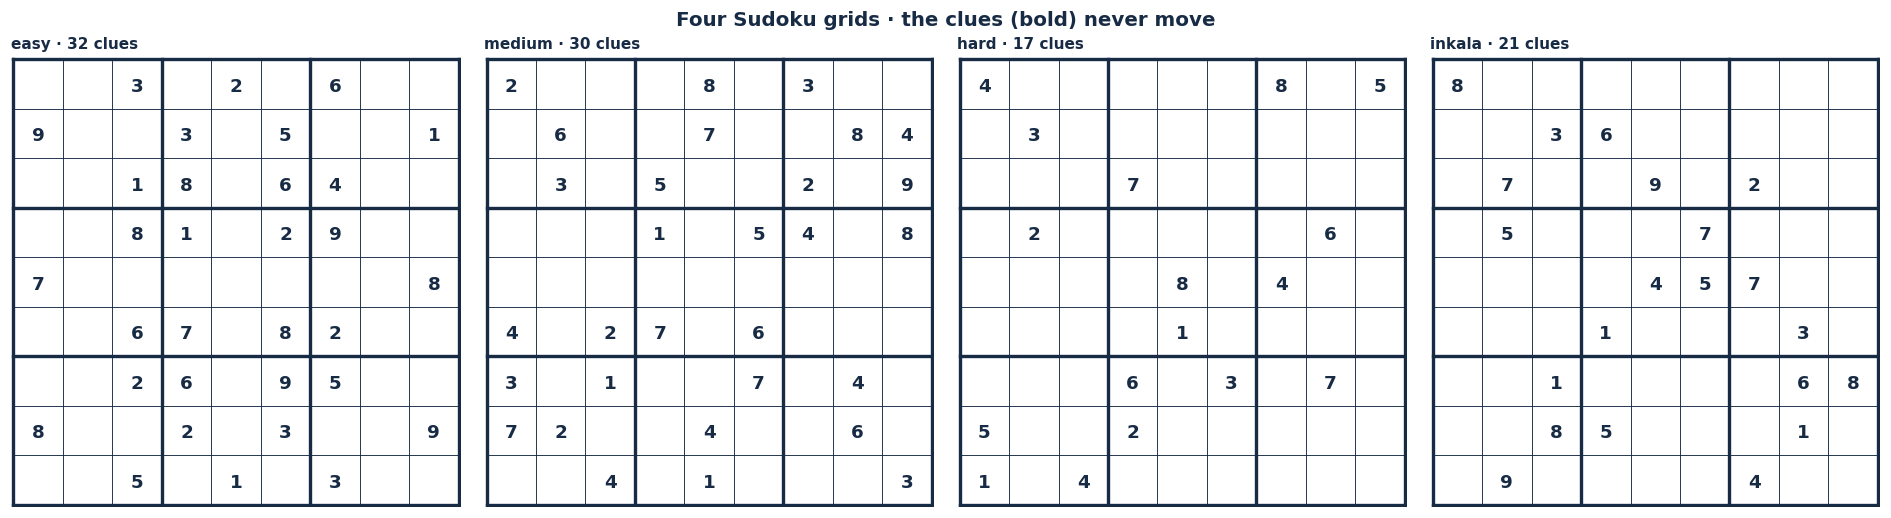

Fill a 9×9 grid so that every **row**, every **column** and every 3×3 **box** contains the digits 1–9 exactly once. The given digits, called clues, must remain unchanged.

In the delivery-tour problem, you searched for a shorter route. Here, you search for a grid that satisfies all the rules. To approach Sudoku with our search methods, you will define candidate grids, a way to modify them, and a cost that measures conflicts. **A cost of 0 must correspond exactly to a solved Sudoku**.

The challenge is to move from a grid containing conflicts to a valid solution. Several grids may have the same cost, and reducing one conflict may introduce another. How effectively can your methods explore this search space, escape local minima and find a solution?

Later, we will revisit Sudoku through **constraint satisfaction problems (CSPs)**, another way to model and solve problems defined by rules.

**Your task.** This section is free: no code is supplied. Design, implement and defend your own solution, reusing your Section 1–6 code wherever it applies.

1. **Model.** Choose a representation of a state, a cost that is 0 exactly for a solved grid, and one or more moves. State which constraints your representation satisfies by construction and which ones the cost penalises, estimate the size of your search space, and check your model before searching: clues kept, valid neighbours, inputs never modified, cost 0 on a solved grid.
2. **Solve with two methods: HC + GA, or SA + GA.** Adapt your solvers and your genetic operators to your representation, count every evaluation as in Sections 3–5, and stop as soon as a grid is solved.
3. **Tune.** For each method, study at least two hyperparameters, one factor at a time, with several seeds and a fixed `max_steps`; choose the numbers of steps so that your two methods evaluate about the same number of grids. Report the fraction of solved runs, the evaluations used by the solved runs, the final cost and the time.
4. **Compare.** Freeze one configuration per method from the tuning evidence only, then compare the two on fresh seeds, on the grid used for tuning and on at least one grid never used for tuning.
5. **Justify and discuss** (400–600 words, with your numbers). Justify every implementation and hyperparameter choice; explain the differences between your two methods through their mechanisms; say what transferred from the delivery tour (code, settings, conclusions) and what did not; give one limitation of your protocol; and say when you would not use local search at all for a Sudoku.

Present the evidence as in Sections 3–6: implementation and checks, one trace per method, tables and figures for the studies, the frozen comparison, then the discussion. This section is personal work, like the studies of Section 6.

**The grids**, read row by row (0 = empty cell). Tune on "easy"; keep the others to test your conclusions.

| Grid | Clues | The 81 cells |
|:---|---:|:---|
| easy | 32 | 003020600900305001001806400008102900700000008006708200002609500800203009005010300 |
| medium | 30 | 200080300060070084030500209000105408000000000402706000301007040720040060004010003 |
| hard | 17 | 400000805030000000000700000020000060000080400000010000000603070500200000104000000 |
| inkala | 21 | 800000000003600000070090200050007000000045700000100030001000068008500010090000400 |

**Optional tools.** `search_lab/sudoku.py` holds the same grids and their solutions (to measure how far a failed run is from the solution), a grid figure, an interactive player for a run of `run_search`, model and crossover checks, and a summary of repeated runs (solved fraction, evaluations of the solved runs) to use with `benchmark`, `plot_results` and `paired_effect` from Section 6. `run_search` and `benchmark` accept any problem that defines `is_valid(state)`, `cost(state)`, `random_state(rng)`, `neighbors(state, ...)` and `random_neighbor(state, rng, ...)`. Read the docstrings; using these tools is not required.

**Your work.** Add your own cells below: model and checks, your two solvers, traces, studies, frozen comparison and discussion.

## 8 · Submit and prepare to explain

Submit the completed notebook and every file it requires, in a ZIP that keeps the folder structure, **no later than the lab session 4**. Restart the kernel and run all cells before packaging; keep the outputs, the settings and the written answers.

| Before submission | Check |
|:---|:---|
| Implementations | I1–I6 complete: two neighbourhoods, HC, acceptance and two schedules, SA, GA operators and loop; Section 7: your Sudoku model and your two methods (HC + GA or SA + GA), with their checks |
| Written answers | Q0–Q12 answered next to their evidence; Section 7: the justification and discussion |
| Studies | E1–E3 with 20 tuning seeds; frozen configurations tested on the 20 test seeds; Section 7: tuning studies and a frozen comparison on fresh seeds and on a grid not used for tuning |
| Figures | One move, one trace per method, final tours, convergence/quality/time figures; Section 7: one Sudoku trace per method |
| Reproducibility | Seeds, complete settings (including `max_steps`), versions, steps and evaluations actually used |
| Interpretation | Numbers, variability, limitations; no unsupported optimality claim |

Assessment focuses on correctness, reproducibility and explanation. Be ready to answer questions such as:

1. What is a neighbour in local search? Define it for the tour representation and give the size of each neighbourhood.
2. Why use random restarts in hill climbing? What do they change in the trace, in the steps and in the evaluations used?
3. What impact did the choice of neighbour generation (swap or 2-opt) have on hill climbing and on simulated annealing in your runs?
4. What is the impact of the cooling schedule (shape, T0, Tf) on simulated annealing?
5. Why do we repeat the runs with several seeds instead of trusting a single run of a local-search method?
6. Trace selection, crossover and mutation for one child; count the evaluations of one generation.
7. Defend one numerical conclusion and propose evidence that could challenge it.
8. State which Sudoku constraints your representation guarantees; trace one move and one crossover on it.
9. Explain which setting of the map transferred to the Sudoku and which did not, and why.